In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

In [47]:
exp_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/exp_insert_e2&noDP.csv')
FIL_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/FIL_insert_e2.csv')

In [48]:
# val_ycols = [col for col in val_df.columns if col.endswith('Validation accuracy')]
# train_ycols = [col for col in train_df.columns if col.endswith('Training Loss')]

# print(len(val_ycols))
# print(len(train_ycols))
# print(val_ycols)
# print(train_ycols)

In [49]:
FIL_xcol = 'Step'
FIL_ycol = 'FIL,epsilon=2 - FIL'
FIL_baseline_ycol = 'Base_FIL,epsilon=2 - Baseline FIL'
exp_noDP_ycol = 'Exposure, No DP - Exposure'
exp_eps2_ycol = 'Exposure, Epsilon=2 - Exposure'
exp_xcol = 'Number of insertions of Canary'

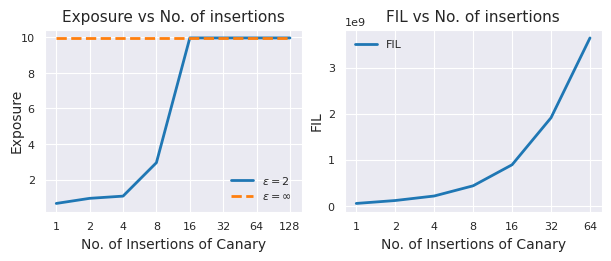

In [ ]:
from matplotlib.ticker import MaxNLocator

fig, axs = plt.subplots(1, 2, figsize=(6,2.5), constrained_layout=True)

# --- Plot 1 (Left): Exposure vs Insertions ---
axs[0].plot(exp_df[exp_xcol], exp_df[exp_eps2_ycol],
            label=r'$\epsilon = 2$', color='C0', linewidth=2)
axs[0].plot(exp_df[exp_xcol], exp_df[exp_noDP_ycol],
            label=r'$\epsilon = \infty$', color='C1', linestyle='--', linewidth=2)

axs[0].set_xlabel('No. of Insertions of Canary', fontsize=10)
axs[0].set_ylabel('Exposure', fontsize=10, labelpad=8)
axs[0].tick_params(labelsize=8)
axs[0].yaxis.set_label_coords(-0.08, 0.5)
axs[0].legend(fontsize=8, title_fontsize=9, frameon=False)
axs[0].set_title('Exposure vs No. of insertions', fontsize=11)
tick_positions = [0,1, 2, 3, 4, 5, 6, 7]
axs[0].set_xticks(tick_positions)
axs[0].set_xticklabels(['1','2','4','8','16','32','64','128'])

axs[1].plot(FIL_df[FIL_xcol], FIL_df[FIL_ycol],
            label='FIL', color='C0', linewidth=2)
# axs[1].plot(FIL_df[FIL_xcol], FIL_df[FIL_baseline_ycol],
#             label='Baseline FIL', color='C1', linestyle='--', linewidth=2)

axs[1].set_xlabel('No. of Insertions of Canary', fontsize=10)
axs[1].set_ylabel('FIL', fontsize=10, labelpad=8)
# axs[1].set_yscale('log')
axs[1].tick_params(labelsize=8)
axs[1].yaxis.set_label_coords(-0.08, 0.5)
axs[1].legend(fontsize=8, title_fontsize=9, frameon=False)
axs[1].set_title('FIL vs No. of insertions', fontsize=11)
axs[1].yaxis.offsetText.set_fontsize(8)
axs[1].yaxis.set_major_locator(MaxNLocator(nbins=4))
axs[1].xaxis.set_major_locator(MaxNLocator(nbins=4))
tick_positions = [0,1, 2, 3, 4, 5, 6]
axs[1].set_xticks(tick_positions)
axs[1].set_xticklabels(['1','2','4','8','16','32','64'])

plt.savefig("pdfs_save/insert_exp&FIL.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()